# Plot the flight tracks of the Loon and Concordiasi balloons

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

import matplotlib.colors as mcolors

### Load the data

In [3]:
# The segments that are analyzed in the rest of the Figure
loon_flight_id = 'I-160'
loon_segment_id = 112
loon_time_start = pd.Timestamp('2014-03-11 18:00') # I-160 Andes crossing
loon_time_stop = pd.Timestamp('2014-03-17 06:00') # I-160 Andes crossing

concordiasi_flight_id = '06'
concordiasi_segment_id = 39
concordiasi_time_start = pd.Timestamp('2010-11-11 00:00') # Flight 04 Antarctic Peninsula crossing
concordiasi_time_stop = pd.Timestamp('2010-11-12 00:00') # Flight 04 Antarctic Peninsula crossing

# Select segments that fly inside a lat/lon box
# Andes:
Andes_lat_box_min = -55
Andes_lat_box_max = -30
Andes_lon_box_min = -80
Andes_lon_box_max = -60

# Antarctic Peninsula:
AP_lat_box_min = -80
AP_lat_box_max = -60
AP_lon_box_min = -75
AP_lon_box_max = -55

# The data
FLUX_THRESHOLD = 50 # (mPa) the threshold of the frequency-integrated total momentum flux
loon_flights = pd.read_feather('Loon_momentum_fluxes_omega0_8_Ep.feather')
concordiasi_flights = pd.read_feather('../concordiasi_strateole2_analysis/Concordiasi_momentum_fluxes_omega0_8_Ep.feather')
loon_flights = loon_flights[loon_flights.latitude <= Andes_lat_box_max]
loon_flights = loon_flights[loon_flights.latitude >= Andes_lat_box_min]
loon_flights = loon_flights[loon_flights.longitude <= Andes_lon_box_max]
loon_flights = loon_flights[loon_flights.longitude >= Andes_lon_box_min]
concordiasi_flights = concordiasi_flights[concordiasi_flights.latitude <= AP_lat_box_max]
concordiasi_flights = concordiasi_flights[concordiasi_flights.latitude >= AP_lat_box_min]
concordiasi_flights = concordiasi_flights[concordiasi_flights.longitude <= AP_lon_box_max]
concordiasi_flights = concordiasi_flights[concordiasi_flights.longitude >= AP_lon_box_min]

loon_flights_fluxthresh = loon_flights[loon_flights.flux_Etotal_scaled > FLUX_THRESHOLD]
concordiasi_flights_fluxthresh = concordiasi_flights[concordiasi_flights.flux_Etotal_scaled > FLUX_THRESHOLD]

### Plot the segments on a map

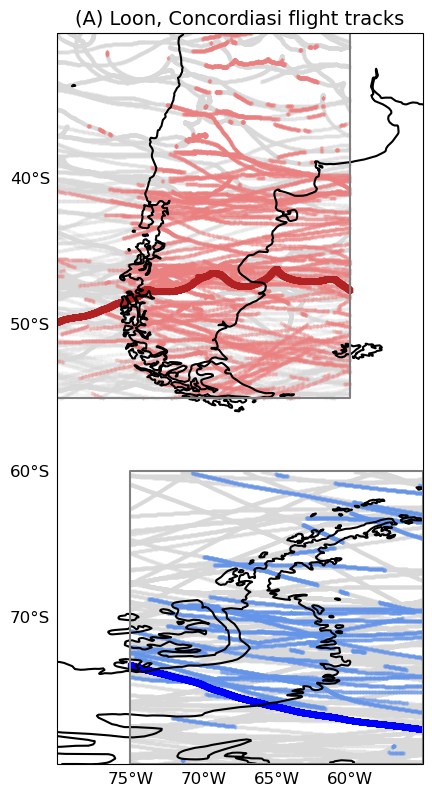

In [4]:
# Fig. 3A

plt.figure(figsize=(9.5,9.5))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=0.0, globe=None))
ax.set_extent([-80, -55, -80, -30], crs=ccrs.PlateCarree())
ax.coastlines(resolution='50m',linewidth=1.5) # Options are 110m, 50m, 10m
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False
gl.xlines = False
gl.ylines = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}
gl.xlocator = mticker.FixedLocator(np.arange(-180.,181.,5))
gl.ylocator = mticker.FixedLocator(np.arange(-90.,91.,10))
plots = np.ndarray(shape=8,dtype='object')

lon = np.array(loon_flights.longitude)
lat = np.array(loon_flights.latitude)
plots[0] = plt.scatter(lon, lat, s=1, marker='s', color=[0.85,0.85,0.85], alpha=0.1, transform=ccrs.PlateCarree())

lon = np.array(loon_flights_fluxthresh.longitude)
lat = np.array(loon_flights_fluxthresh.latitude)
plots[1] = plt.scatter(lon, lat, s=1, marker='s', color=mcolors.CSS4_COLORS['lightcoral'], alpha=0.2, transform=ccrs.PlateCarree())

temp = loon_flights[loon_flights.segment_id == loon_segment_id]
temp = temp[temp.time <= loon_time_stop]
temp = temp[temp.time >= loon_time_start]
lon = np.array(temp.longitude)
lat = np.array(temp.latitude)
plots[2] = plt.scatter(lon, lat, s=5, marker='s', color=mcolors.CSS4_COLORS['firebrick'], alpha=1, transform=ccrs.PlateCarree())

lon = np.array(concordiasi_flights.longitude)
lat = np.array(concordiasi_flights.latitude)
plots[3] = plt.scatter(lon, lat, s=1, marker='s', color=[0.85,0.85,0.85], alpha=0.1, transform=ccrs.PlateCarree())

lon = np.array(concordiasi_flights_fluxthresh.longitude)
lat = np.array(concordiasi_flights_fluxthresh.latitude)
plots[4] = plt.scatter(lon, lat, s=1, marker='s', color=mcolors.CSS4_COLORS['cornflowerblue'], alpha=0.2, transform=ccrs.PlateCarree())

temp = concordiasi_flights[concordiasi_flights.segment_id == concordiasi_segment_id]
temp = temp[temp.time <= concordiasi_time_stop]
temp = temp[temp.time >= concordiasi_time_start]
lon = np.array(temp.longitude)
lat = np.array(temp.latitude)
plots[5] = plt.scatter(lon, lat, s=5, marker='s', color=mcolors.CSS4_COLORS['blue'], alpha=1, transform=ccrs.PlateCarree())

plots[6] = plt.plot([Andes_lon_box_min, Andes_lon_box_min, Andes_lon_box_max, Andes_lon_box_max, Andes_lon_box_min],
                    [Andes_lat_box_min, Andes_lat_box_max, Andes_lat_box_max, Andes_lat_box_min, Andes_lat_box_min],
                    color=[0.5,0.5,0.5], transform=ccrs.PlateCarree())

plots[7] = plt.plot([AP_lon_box_min, AP_lon_box_min, AP_lon_box_max, AP_lon_box_max, AP_lon_box_min],
                    [AP_lat_box_min, AP_lat_box_max, AP_lat_box_max, AP_lat_box_min, AP_lat_box_min],
                    color=[0.5,0.5,0.5], transform=ccrs.PlateCarree())

plt.title('(A) Loon, Concordiasi flight tracks', fontsize=14);

#plt.savefig('../plots/temp11.pdf', format='pdf', bbox_inches='tight');